# Multivariate Analysis

## 1. Introduction

Multivariate analysis is the process of analyzing three or more variables together to understand their relationships and patterns.

In this notebook, I will use Python, Pandas, NumPy, Matplotlib, and Seaborn to analyze multiple features in the dataset.

### Objectives
- Understand relationships among multiple variables.
- Analyze correlations between numerical features.
- Visualize relationships using heatmaps and pair plots.
- Identify patterns that may be useful for machine learning.

## 2. Understanding Multivariate Analysis

Multivariate analysis studies three or more variables at the same time.

For example, Study_Hours, Attendance, and Exam_Marks can be analyzed together to understand how study time and attendance are related to exam performance.

### Example
If students study more hours and attend classes regularly, we can examine whether their exam marks tend to be higher.

**AI/ML relevance:** Multivariate analysis helps identify relationships between features and supports feature selection and model development.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading the Dataset

I will load the `ml_training_data.csv` dataset using Pandas. The dataset will be used throughout this notebook for multivariate analysis.

In [6]:
df = pd.read_csv("ml_training_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5, 3)


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90


## 4. Understanding the Dataset

Before performing multivariate analysis, I will inspect the column names, data types, and summary statistics to understand the dataset.

In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

Column names:
['Study_Hours', 'Attendance', 'Exam_Marks']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  5 non-null      int64
 1   Attendance   5 non-null      int64
 2   Exam_Marks   5 non-null      int64
dtypes: int64(3)
memory usage: 252.0 bytes

Summary statistics:


,Study_Hours,Attendance,Exam_Marks
count,5.000000,5.000000,5.000000
mean,4.000000,76.000000,67.000000
std,1.581139,14.317821,16.046807
min,2.000000,60.000000,50.000000
25%,3.000000,65.000000,55.000000
50%,4.000000,75.000000,65.000000
75%,5.000000,85.000000,75.000000
max,6.000000,95.000000,90.000000


## 5. Selecting Numerical Features

Correlation analysis and many multivariate visualizations work with numerical features. I will select all numerical columns from the dataset.

In [8]:
numerical_df = df.select_dtypes(include="number")

print("Numerical columns:")
print(numerical_df.columns.tolist())

print("\nNumber of numerical columns:", numerical_df.shape[1])

display(numerical_df.head())

Numerical columns:
['Study_Hours', 'Attendance', 'Exam_Marks']

Number of numerical columns: 3


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90


## 6. Correlation Matrix

A correlation matrix shows the direction and strength of linear relationships between numerical variables.

- A value close to +1 indicates a strong positive linear relationship.
- A value close to -1 indicates a strong negative linear relationship.
- A value close to 0 indicates a weak linear relationship.

Correlation does not prove causation.

In [9]:
correlation_matrix = numerical_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Study_Hours,Attendance,Exam_Marks
Study_Hours,1.00,0.99,0.99
Attendance,0.99,1.00,1.00
Exam_Marks,0.99,1.00,1.00


## 7. Correlation Heatmap

A heatmap displays the correlation matrix using colors. It helps us identify positive, negative, and weak relationships between numerical features.

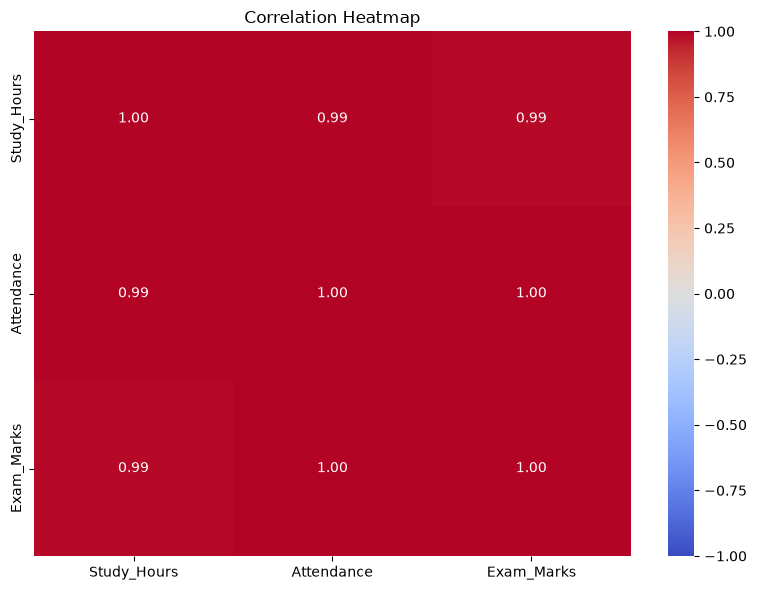

In [10]:
if numerical_df.shape[1] >= 2:
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required.")

## 8. Pair Plot

A pair plot displays scatter plots for pairs of numerical features and distributions for individual features. It helps us observe patterns among multiple variables.

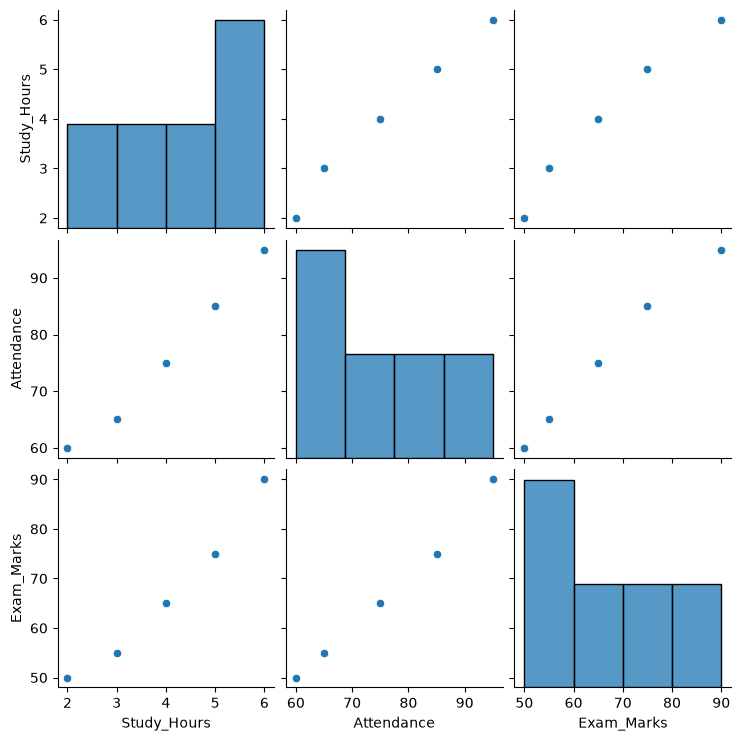

In [11]:
if numerical_df.shape[1] >= 2:
    sns.pairplot(numerical_df)
    plt.show()
else:
    print("At least two numerical columns are required.")

## 9. Analyzing Three Variables Together

In this section, I will analyze Study_Hours, Attendance, and Exam_Marks together. The scatter plot will show study hours against exam marks, while color will represent attendance.

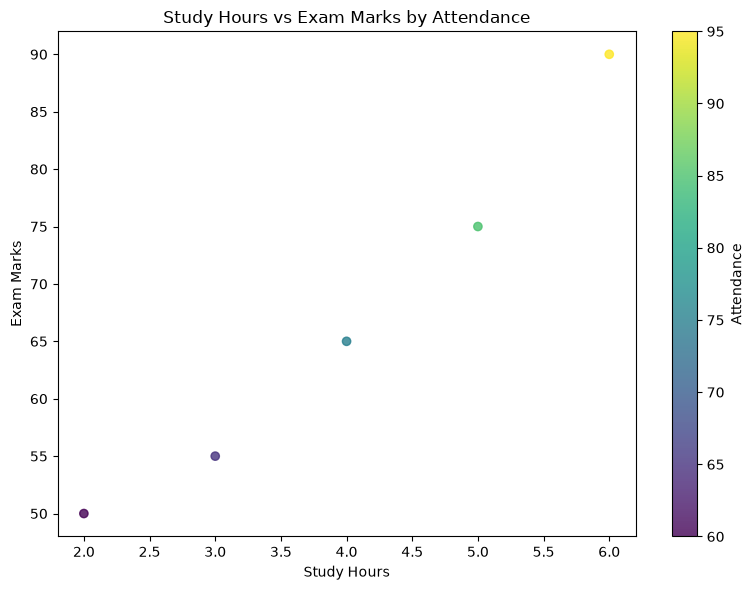

In [12]:
required_columns = ["Study_Hours", "Attendance", "Exam_Marks"]

if all(column in df.columns for column in required_columns):
    plot_df = df[required_columns].dropna()

    plt.figure(figsize=(8, 6))

    scatter = plt.scatter(
        plot_df["Study_Hours"],
        plot_df["Exam_Marks"],
        c=plot_df["Attendance"],
        cmap="viridis",
        alpha=0.8
    )

    plt.xlabel("Study Hours")
    plt.ylabel("Exam Marks")
    plt.title("Study Hours vs Exam Marks by Attendance")

    plt.colorbar(scatter, label="Attendance")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns are not available in the dataset.")

## 10. Identifying Strong Relationships

I will compare the correlations between numerical feature pairs and rank them by the absolute value of their correlation coefficients. This helps identify the strongest linear relationships.

In [13]:
if numerical_df.shape[1] >= 2:
    upper_triangle = correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )

    correlation_pairs = (
        upper_triangle.stack()
        .sort_values(key=lambda values: values.abs(), ascending=False)
    )

    print("Feature pairs ranked by correlation strength:")
    display(correlation_pairs.to_frame(name="Correlation"))
else:
    print("At least two numerical columns are required.")

Feature pairs ranked by correlation strength:


Correlation
Attendance  Exam_Marks      0.995624
Study_Hours Attendance      0.993884
            Exam_Marks      0.985329
            Study_Hours          NaN
Attendance  Study_Hours          NaN
            Attendance           NaN
Exam_Marks  Study_Hours          NaN
            Attendance           NaN
            Exam_Marks           NaN

## 11. Checking Missing Values

Missing values can affect data analysis and machine learning. I will check the number of missing values in each column before interpreting the results.

In [14]:
print("Missing values in each column:")
display(df.isnull().sum())

Missing values in each column:


Study_Hours    0
Attendance     0
Exam_Marks     0
dtype: int64

## 12. Observations and Insights

1. The correlation heatmap helps identify relationships between numerical features.
2. The pair plot helps visualize relationships and distributions among multiple features.
3. The combined scatter plot shows the relationship between Study_Hours and Exam_Marks, with Attendance represented by color.
4. The correlation matrix helps identify feature pairs with stronger linear relationships.
5. Missing values should be investigated before using the dataset for machine learning.
6. Any unexpected patterns or outliers should be checked before drawing conclusions.

**Note:** The final observations should be updated based on the actual correlation values and visualizations produced by the notebook.

## 13. AI/ML Relevance

Multivariate analysis is useful in machine learning because it helps us understand relationships among features, identify potentially redundant features, and support feature selection.

It also helps us explore which features may be useful for predicting a target variable. However, correlation alone is not enough to determine which features should be included in a model.